<a href="https://colab.research.google.com/github/MITS-CAI/DL/blob/main/5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Test Accuracy: 0.8


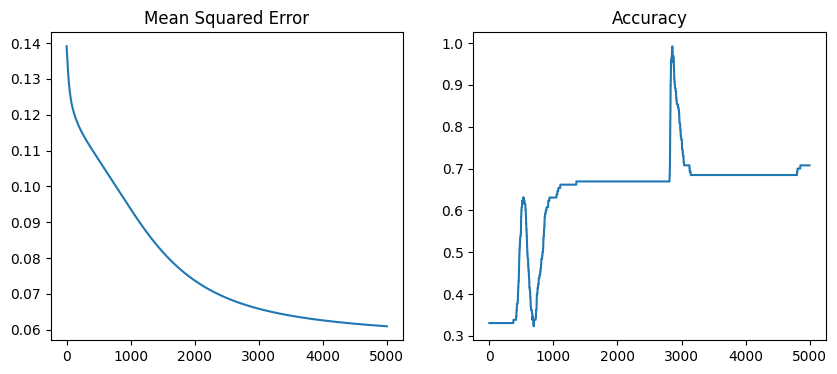

In [48]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split

# 1. Load & prepare Iris data
iris = load_iris()
x = iris.data
y = pd.get_dummies(iris.target, dtype=int).values

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=20, random_state=4)

# 2. Initialize hyperparameters & random weights
lr = 0.1
iterations = 5000
N = y_train.size
np.random.seed(10)

W1 = np.random.normal(scale=0.5, size=(4, 2))   # Input (4) -> Hidden (2)
W2 = np.random.normal(scale=0.5, size=(2, 3))   # Hidden (2) -> Output (3)

# 3. Helper functions
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def accuracy(y_pred, y_true):
    return (y_pred.argmax(axis=1) == y_true.argmax(axis=1)).mean()

# 4. Train with Backpropagation
mse_list, acc_list = [], []

for i in range(iterations):
    # Feedforward
    A1 = sigmoid(np.dot(x_train, W1))
    A2 = sigmoid(np.dot(A1, W2))

    # Track error & accuracy
    mse = ((A2 - y_train) ** 2).sum() / (2 * A2.size)
    mse_list.append(mse)
    acc_list.append(accuracy(A2, y_train))

    # Backpropagation
    dW1 = (A2 - y_train) * A2 * (1 - A2)
    dW2 = np.dot(dW1, W2.T) * A1 * (1 - A1)

    # Update weights
    W2 -= lr * (np.dot(A1.T, dW1) / N)
    W1 -= lr * (np.dot(x_train.T, dW2) / N)

# 5. Evaluate on test data
A1_test = sigmoid(np.dot(x_test, W1))
A2_test = sigmoid(np.dot(A1_test, W2))
print("Test Accuracy:", accuracy(A2_test, y_test))

# 6. Plot MSE and Accuracy curves
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(mse_list)
plt.title("Mean Squared Error")

plt.subplot(1, 2, 2)
plt.plot(acc_list)
plt.title("Accuracy")
plt.show()